# Logistics Delivery Performance: How Often Are Trucks Late, and Why?

**Data:** Transportation and Logistics Tracking Dataset: 6,880 truck trips across India (2019 to 2020), sheet *Primary data*.

**Questions**
1. How many trips arrive late, and by how much?
2. Which customers, transport suppliers, vehicle types, distances and routes have the worst on-time performance?
3. Can we trust the tracking data, and where is it weakest?
4. What should operations do first?

**Approach:** keep every usable trip, use the dataset's own on-time/late labels (checked against the timestamps), and only rank groups with enough trips to be reliable.

In [2]:
%pip install openpyxl


   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpy


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

# Chart style: one blue for data, grey for reference lines, quiet axes
BLUE, GREY, INK, INK2 = "#2a78d6", "#8f8e89", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#d6d5d0", "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "font.size": 10,
})

# Find the Excel file: on Kaggle (/kaggle/input), next to this notebook, or in Downloads/Desktop/Documents.
# If only the downloaded .zip is found, unzip it next to this notebook first.
import zipfile
home = os.path.expanduser("~")
places = ["/kaggle/input", ".", os.path.join(home, "Downloads"), os.path.join(home, "Desktop"), os.path.join(home, "Documents")]

def find(pattern):
    for place in places:
        if os.path.isdir(place):
            hits = glob.glob(os.path.join(place, "**", pattern), recursive=True)
            if hits:
                return hits[0]
    return None

PATH = find("*Logistics*Tracking*.xlsx")
if PATH is None:
    zip_path = find("*Logistics*Tracking*.zip")
    if zip_path:
        with zipfile.ZipFile(zip_path) as z:
            name = [n for n in z.namelist() if n.endswith(".xlsx")][0]
            z.extract(name, ".")
        PATH = os.path.join(".", name)
        print("Unzipped:", zip_path)
assert PATH, ("Couldn't find the dataset. On Kaggle: add 'Transportation and Logistics Tracking Dataset' as Input. "
              "On your PC: put the .xlsx (or its .zip) next to this notebook.")
raw = pd.read_excel(PATH, sheet_name="Primary data")
print("File :", PATH)
print("Shape:", raw.shape)
raw.head(3)

File : .\Transportation and Logistics Tracking Dataset..xlsx
Shape: (6880, 32)


,GpsProvider,BookingID,Market/Regular,BookingID_Date,vehicle_no,Origin_Location,Destination_Location,Org_lat_lon,Des_lat_lon,Data_Ping_time,Planned_ETA,Current_Location,DestinationLocation,actual_eta,Curr_lat,Curr_lon,ontime,delay,OriginLocation_Code,DestinationLocation_Code,trip_start_date,trip_end_date,TRANSPORTATION_DISTANCE_IN_KM,vehicleType,Minimum_kms_to_be_covered_in_a_day,Driver_Name,Driver_MobileNo,customerID,customerNameCode,supplierID,supplierNameCode,Material Shipped
0,CONSENT TRACK,MVCV0000927/082021,Market,2020-08-17 14:59:01.000,KA590408,"TVSLSL-PUZHAL-HUB,CHENNAI,TAMIL NADU","ASHOK LEYLAND PLANT 1- HOSUR,HOSUR,KARNATAKA","13.1550,80.1960","12.7400,77.8200",2020-08-24 00:05:09,2020-08-21 18:59:01,"Vaniyambadi Rd, Valayambattu, Tamil Nadu 63575...","ASHOK LEYLAND PLANT 1- HOSUR,HOSUR,KARNATAKA",2020-08-28 14:38:04.447000,12.663500,78.649870,NaN,R,CHEPUZTVSHUA1,HOSHOSALLCCA2,2020-08-17 14:59:01,NaN,320.0,32 FT Single-Axle 7MT - HCV,NaN,NaN,NaN,ALLEXCHE45,Ashok leyland limited,VIJEXHOSR7,VIJAY TRANSPORT,BRACKET / GRAB HANDLE
1,VAMOSYS,VCV00014271/082021,Regular,2020-08-27 16:22:22.827,TN30BC5917,"DAIMLER INDIA COMMERCIAL VEHICLES,KANCHIPURAM,...","DAIMLER INDIA COMMERCIAL VEHICLES,KANCHIPURAM,...","12.8390,79.9540","12.8390,79.9540",2020-08-28 12:40:28,2020-08-31 20:22:22.827000,"Unnamed Road, Oragadam Industrial Corridor, Va...","DAIMLER INDIA COMMERCIAL VEHICLES,KANCHIPURAM,...",2020-08-28 12:46:17.007000,12.836757,79.954428,G,NaN,CHEORADMRCCB1,CHEMATDMROPA7,2020-08-27 16:21:52,NaN,103.0,32 FT Multi-Axle 14MT - HCV,NaN,RAMESH,NaN,DMREXCHEUX,Daimler india commercial vehicles pvt lt,VJLEXSHE09,VJ LOGISTICS,ZB MODEL PLATE / 3143
2,CONSENT TRACK,VCV00014382/082021,Regular,2020-08-27 17:59:24.987,TN22AR2748,"LUCAS TVS LTD-PONDY,PONDY,PONDICHERRY","LUCAS TVS LTD-PONDY,PONDY,PONDICHERRY","11.8710,79.7390","11.8710,79.7390",2020-08-28 09:05:09,2020-08-31 21:59:24.987000,"570, National Hwy 48, Shenoy Nagar, Chennai, T...","LUCAS TVS LTD-PONDY,PONDY,PONDICHERRY",2020-08-28 16:03:30.793000,13.073956,80.225780,G,NaN,CHEPONLUTCCA4,CHEPONLUTCCA4,2020-08-27 17:57:04,NaN,300.0,1 MT Tata Ace (Open Body),NaN,GIRI,NaN,LUTGCCHE06,Lucas tvs ltd,GSTEXLAK1Q,G.S. TRANSPORT,LETTERING / FUSO


## 1. Data audit

Before measuring anything: what is missing, what is duplicated, and which values are impossible.

In [4]:
audit = pd.DataFrame({
    "missing": raw.isna().sum(),
    "missing_%": (raw.isna().mean() * 100).round(1),
    "unique": raw.nunique(),
}).sort_values("missing_%", ascending=False)
audit[audit["missing"] > 0]

,missing,missing_%,unique
ontime,4332,63.0,1
Driver_MobileNo,4189,60.9,1273
Minimum_kms_to_be_covered_in_a_day,4060,59.0,3
Driver_Name,3429,49.8,1355
delay,2538,36.9,1
Current_Location,964,14.0,2567
Data_Ping_time,953,13.9,3756
GpsProvider,953,13.9,29
Curr_lon,953,13.9,4109
Curr_lat,953,13.9,4139


In [5]:
dates = ["BookingID_Date", "Data_Ping_time", "Planned_ETA", "actual_eta", "trip_start_date", "trip_end_date"]
df = raw.copy()
df.columns = df.columns.str.strip()
for c in dates:   # some cells hold Excel "zero" dates (1899-12-30) or numbers instead of dates
    df[c] = pd.to_datetime(df[c].astype(str), errors="coerce", format="mixed")
    df.loc[df[c].dt.year < 2000, c] = pd.NaT

print("Exact duplicate rows      :", df.duplicated().sum())
print("Repeated BookingIDs       :", df["BookingID"].duplicated().sum())
print("Trips with no planned ETA :", df["Planned_ETA"].isna().sum())
print("Trips with no actual ETA  :", df["actual_eta"].isna().sum())
print("Trips with no GPS provider:", df["GpsProvider"].isna().sum())
print("Official labels  ->  ontime='G':", df["ontime"].eq("G").sum(), "| delay='R':", df["delay"].eq("R").sum(),
      "| neither:", (df["ontime"].isna() & df["delay"].isna()).sum())

Exact duplicate rows      : 0
Repeated BookingIDs       : 5
Trips with no planned ETA : 2
Trips with no actual ETA  : 39
Trips with no GPS provider: 953
Official labels  ->  ontime='G': 2548 | delay='R': 4342 | neither: 14


**Cleaning decisions**
- Drop repeated BookingIDs (same booking entered twice) and trips with an invalid planned or actual ETA.
- **Late = the dataset's own label** (`delay = "R"` means late, `ontime = "G"` means on time). The check below shows it matches *actual ETA > planned ETA* for ~99% of trips, so we can use it for every trip instead of throwing data away.
- `delay_hours` = actual ETA − planned ETA, used to measure *how* late.
- Fix inconsistent text: vehicle types written as `24 / 26 FT` and `24 | 26 FT` are the same truck.
- Driver phone numbers are dropped: they aren't needed and are personal data.

In [6]:
df = df.drop_duplicates(subset="BookingID", keep="first")
df = df.dropna(subset=["Planned_ETA", "actual_eta"]).drop(columns=["Driver_MobileNo"])

df["delay_hours"] = (df["actual_eta"] - df["Planned_ETA"]).dt.total_seconds() / 3600
df["late"] = np.select([df["delay"].eq("R"), df["ontime"].eq("G")], [1, 0], default=np.nan)
df["late"] = df["late"].fillna((df["delay_hours"] > 0).astype(float))   # unlabelled trips: use timestamps

agree = ((df["delay_hours"] > 0).astype(int) == df["late"]).mean()
print(f"Label agrees with timestamps for {agree:.1%} of trips")

df["vehicleType"] = df["vehicleType"].str.replace(" | ", " / ", regex=False).str.strip()
df["route"] = df["Origin_Location"].str.strip() + "  →  " + df["Destination_Location"].str.strip()
df["distance_band"] = pd.cut(df["TRANSPORTATION_DISTANCE_IN_KM"], [0, 100, 300, 600, 1000, 1e6],
                             labels=["<100 km", "100–300 km", "300–600 km", "600–1000 km", "1000+ km"])
df["month"] = df["trip_start_date"].dt.to_period("M")
df["gps"] = df["GpsProvider"].fillna("No GPS provider")
print("Clean trips:", len(df), f"(kept {len(df)/len(raw):.1%} of the raw rows)")

Label agrees with timestamps for 99.4% of trips
Clean trips: 6836 (kept 99.4% of the raw rows)


## 2. A measurement problem: untracked trips look "on time" by default

Before computing KPIs, check *how* arrival times were recorded. If arrival times are copied from the plan instead of measured, those trips will always look on time.

In [7]:
no_gps = df[df["gps"] == "No GPS provider"]
print(f"Trips without a GPS provider: {len(no_gps)}")
print("Their delay (actual − planned ETA), in hours:")
print(no_gps["delay_hours"].round(2).value_counts().head(3).to_string())

by_month = df.groupby("month").agg(
    trips=("late", "size"),
    share_without_gps_pct=("gps", lambda s: round((s == "No GPS provider").mean() * 100)),
    late_rate_pct=("late", lambda s: round(s.mean() * 100, 1)),
    median_delay_h=("delay_hours", lambda s: round(s.median(), 1)),
)
by_month[by_month["trips"] >= 30]

Trips without a GPS provider: 952
Their delay (actual − planned ETA), in hours:
delay_hours
-0.75    952


,trips,share_without_gps_pct,late_rate_pct,median_delay_h
month,,,,
2019-03,264,90,1.1,-0.8
2019-04,274,93,0.7,-0.8
2019-05,377,94,0.5,-0.8
2019-06,192,54,44.3,-0.8
2019-07,120,0,96.7,50.4
2019-08,53,0,100.0,158.8
2019-09,304,0,100.0,1125.8
2019-10,524,0,98.3,494.4
2019-11,638,0,99.4,153.8


**What this shows:** every trip without GPS has *exactly the same* delay (−0.75 h). Its "actual ETA" was not measured; it was set from the plan. These trips are almost all from March to June 2019, and they are the reason those months look perfect.

**Decision:** KPIs and rankings below use **GPS-tracked trips only** (`tracked`). Untracked trips can't tell us whether a truck was late.

In [8]:
tracked = df[df["gps"] != "No GPS provider"].copy()
print(f"GPS-tracked trips used for the KPIs: {len(tracked):,} of {len(df):,}")

GPS-tracked trips used for the KPIs: 5,884 of 6,836


## 3. Headline KPIs (GPS-tracked trips)

In [9]:
late_rate = tracked["late"].mean()
late_trips = tracked[tracked["late"] == 1]
kpi = pd.Series({
    "Tracked trips analysed": f"{len(tracked):,}",
    "Late trips": f"{int(df['late'].sum()):,}",
    "Late rate": f"{late_rate:.1%}",
    "On-time rate": f"{1-late_rate:.1%}",
    "(Late rate if untracked trips were wrongly counted)": f"{df['late'].mean():.1%}",
    "Median delay of a late trip": f"{late_trips['delay_hours'].median():.0f} hours",
    "Late trips more than 1 day late": f"{(late_trips['delay_hours'] > 24).mean():.0%}",
    "Late trips more than 1 week late": f"{(late_trips['delay_hours'] > 168).mean():.0%}",
    "Late trips more than 30 days late (likely never closed in the system)": f"{(late_trips['delay_hours'] > 720).mean():.0%}",
})
kpi.to_frame("value")

,value
Tracked trips analysed,"5,884"
Late trips,"4,323"
Late rate,73.5%
On-time rate,26.5%
(Late rate if untracked trips were wrongly counted),63.2%
Median delay of a late trip,140 hours
Late trips more than 1 day late,89%
Late trips more than 1 week late,42%
Late trips more than 30 days late (likely never closed in the system),14%


### Why "keep only trips within ±1 day" gives the wrong answer

A common shortcut is to treat any trip more than 24 hours early or late as an outlier and delete it. In this data that deletes most trips, and almost all of the deleted ones are **late**. The on-time rate then looks far better than it really is.

In [10]:
window = df[df["delay_hours"].abs() < 24]
compare = pd.DataFrame({
    "trips": [len(df), len(window)],
    "on-time rate": [f"{1-df['late'].mean():.1%}", f"{1-window['late'].mean():.1%}"],
}, index=["All clean trips (this analysis)", "Only trips within ±24 h"])
print(f"The ±24 h filter removes {1-len(window)/len(df):.0%} of trips; "
      f"{(df.loc[~df.index.isin(window.index), 'late']).mean():.0%} of the removed trips were late.")
compare

The ±24 h filter removes 72% of trips; 77% of the removed trips were late.


,trips,on-time rate
All clean trips (this analysis),6836,36.8%
Only trips within ±24 h,1883,74.0%


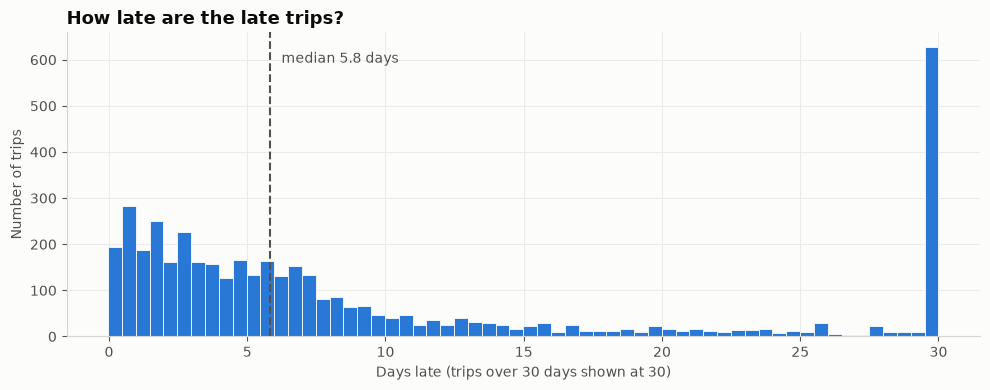

In [11]:
fig, ax = plt.subplots(figsize=(10, 4))
d = late_trips["delay_hours"].clip(upper=24 * 30) / 24
ax.hist(d, bins=60, color=BLUE, edgecolor="#fcfcfb", linewidth=0.6)
med = late_trips["delay_hours"].median() / 24
ax.axvline(med, color=INK2, linestyle="--", linewidth=1.5)
ax.text(med + 0.4, ax.get_ylim()[1] * 0.9, f"median {med:.1f} days", color=INK2)
ax.set_title("How late are the late trips?")
ax.set_xlabel("Days late (trips over 30 days shown at 30)")
ax.set_ylabel("Number of trips")
plt.tight_layout(); plt.show()

**Takeaways**
- About **3 in 4 tracked trips arrive late** (73.5%). Counting the untracked trips as "on time" would wrongly lower this to 63%.
- Being late usually means **days, not hours**. The median late trip arrives about **6 days** (140 h) after plan, and 42% of late trips are more than a week late.
- **14% of late trips (622) are more than 30 days late.** A truck is very unlikely to be a month late, so these trips were probably never closed in the system. That's a process problem in its own right.
- Keeping only trips within ±24 h, as a common shortcut does, removes 72% of trips (77% of them late) and reports a false 74% on-time rate.

## 4. Trend over time

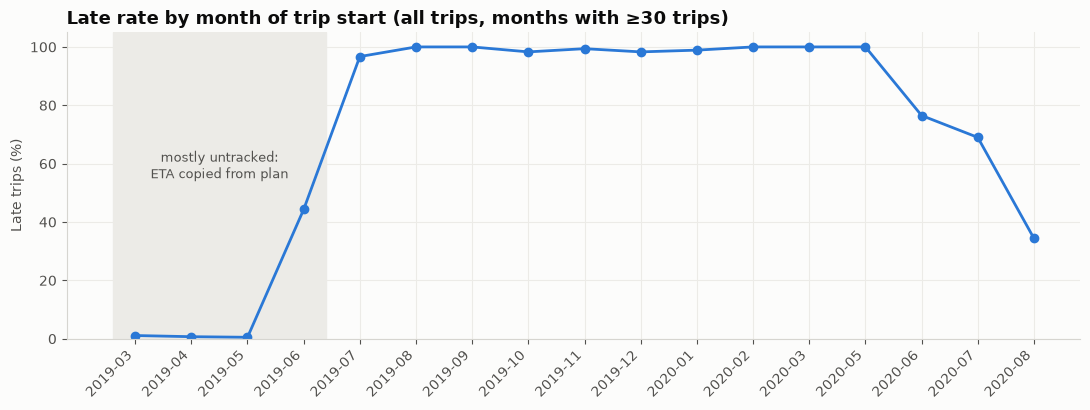

In [12]:
monthly = by_month[by_month["trips"] >= 30]       # skip months with too few trips to judge
fig, ax = plt.subplots(figsize=(11, 4.2))
x = np.arange(len(monthly))
ax.plot(x, monthly["late_rate_pct"], color=BLUE, linewidth=2, marker="o", markersize=6)
untracked = np.where(monthly["share_without_gps_pct"] > 50)[0]
if len(untracked):
    ax.axvspan(untracked.min() - 0.4, untracked.max() + 0.4, color="#ecebe7", zorder=0)
    ax.text(untracked.mean(), 55, "mostly untracked:\nETA copied from plan", ha="center", color=INK2, fontsize=9)
ax.set_xticks(x, monthly.index.astype(str), rotation=45, ha="right")
ax.set_ylim(0, 105); ax.set_ylabel("Late trips (%)")
ax.set_title("Late rate by month of trip start (all trips, months with ≥30 trips)")
plt.tight_layout(); plt.show()

**Takeaways**
- The months before July 2019 look perfect only because they were **not tracked** (the grey band).
- From July 2019 to May 2020, **almost every trip is late**, mostly Larsen & Toubro shipments tracked by CONSENT TRACK.
- **Late rates fall steadily in mid-2020**: 77% in June, 69% in July, 34% in August. August 2020 is the best tracked month, partly because the customer mix shifts toward Daimler, Lucas TVS and Ashok Leyland, who are usually on time.

## 5. Where are the delays concentrated? (GPS-tracked trips)

Each chart ranks groups by late rate, **only for groups with at least 50 trips** (30 for routes), so a single bad trip can't put a group at the top. The grey dotted line is the overall tracked late rate.

In [13]:
def late_table(col, min_trips=50, data=None):
    data = tracked if data is None else data
    t = (data.groupby(col, observed=True)
           .agg(trips=("late", "size"), late_rate=("late", "mean"),
                median_delay_h_when_late=("delay_hours", lambda s: s[data.loc[s.index, "late"] == 1].median()))
           .query("trips >= @min_trips").sort_values("late_rate", ascending=False))
    t["late_rate"] = (t["late_rate"] * 100).round(1)
    t["median_delay_h_when_late"] = t["median_delay_h_when_late"].round(0)
    return t

def late_bar(t, title, top=12, label_width=45):
    t = t.head(top).iloc[::-1]
    names = [n if len(str(n)) <= label_width else str(n)[:label_width - 1] + "…" for n in t.index.astype(str)]
    fig, ax = plt.subplots(figsize=(10, 0.42 * len(t) + 1.2))
    ax.barh(names, t["late_rate"], color=BLUE, height=0.6)
    ax.axvline(late_rate * 100, color=GREY, linestyle=":", linewidth=1.5)
    for i, (r, n) in enumerate(zip(t["late_rate"], t["trips"])):
        ax.text(r + 1, i, f"{r:.0f}%  (n={n})", va="center", color=INK2, fontsize=9)
    ax.set_xlim(0, 115); ax.set_xlabel("Late trips (%)"); ax.grid(axis="y", visible=False)
    ax.set_title(title); plt.tight_layout(); plt.show()

### 5a. By customer

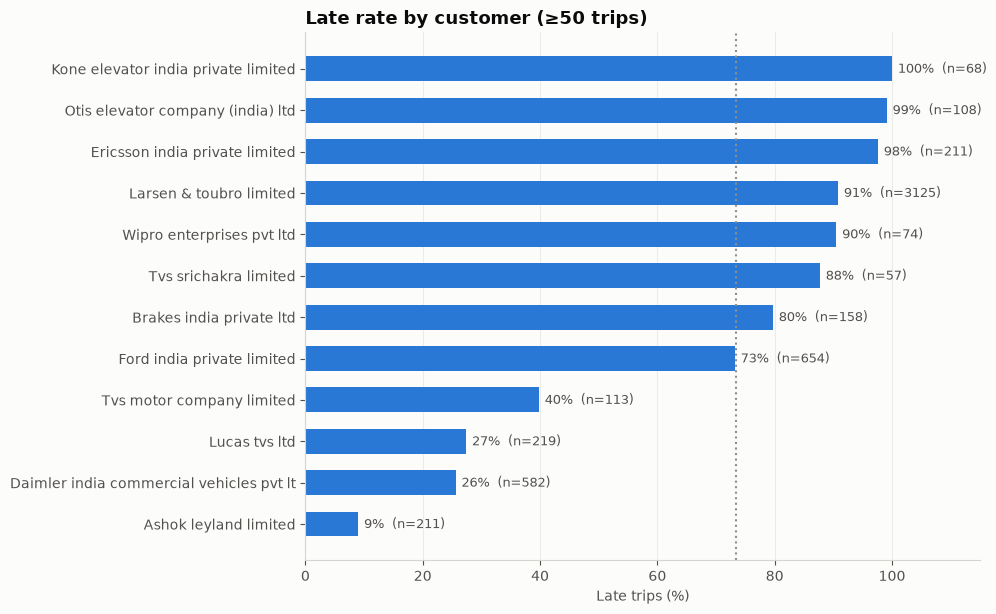

,trips,late_rate,median_delay_h_when_late
customerNameCode,,,
Kone elevator india private limited,68,100.0,266.0
Otis elevator company (india) ltd,108,99.1,204.0
Ericsson india private limited,211,97.6,119.0
Larsen & toubro limited,3125,90.8,162.0
Wipro enterprises pvt ltd,74,90.5,110.0
Tvs srichakra limited,57,87.7,146.0
Brakes india private ltd,158,79.7,83.0
Ford india private limited,654,73.2,55.0
Tvs motor company limited,113,39.8,78.0


In [14]:
by_customer = late_table("customerNameCode")
late_bar(by_customer, "Late rate by customer (≥50 trips)")
by_customer

**Takeaways**
- Performance differs hugely by customer: **Ashok Leyland (9%), Daimler (26%) and Lucas TVS (27%)** are mostly on time, while **Kone, Otis and Ericsson are late on 98–100% of trips**.
- **Larsen & Toubro** is by far the biggest customer (3,125 tracked trips) and is late on **91%** of them, so it drives most of the overall number. Its trips improved from 96% late in 2019 to 75% in 2020.
- The on-time customers are mostly short, regular automotive runs around Chennai, Hosur and Pondicherry, a model worth copying.

### 5b. By transport supplier

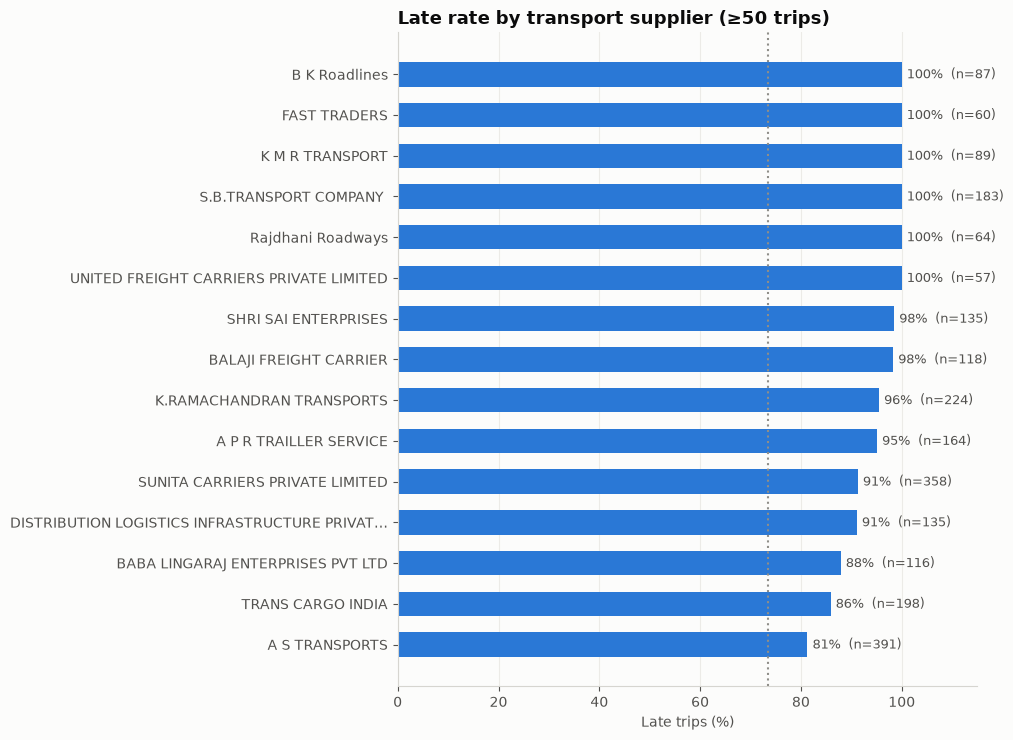

,trips,late_rate,median_delay_h_when_late
supplierNameCode,,,
B K Roadlines,87,100.0,172.0
FAST TRADERS,60,100.0,605.0
K M R TRANSPORT,89,100.0,111.0
S.B.TRANSPORT COMPANY,183,100.0,550.0
Rajdhani Roadways,64,100.0,106.0
UNITED FREIGHT CARRIERS PRIVATE LIMITED,57,100.0,156.0
SHRI SAI ENTERPRISES,135,98.5,232.0
BALAJI FREIGHT CARRIER,118,98.3,270.0
K.RAMACHANDRAN TRANSPORTS,224,95.5,145.0


In [15]:
by_supplier = late_table("supplierNameCode").drop(index="Unknown", errors="ignore")
late_bar(by_supplier, "Late rate by transport supplier (≥50 trips)", top=15)
by_supplier

**Takeaways**
- **Six transport suppliers were late on every single tracked trip** (at least 57 trips each), and several more are above 95%.
- The late *amount* also differs a lot. S.B. Transport and Fast Traders run **550–600 hours** (over 3 weeks) behind when late, which suggests trips left open rather than slow driving.
- Suppliers serve different customers and periods, so use this list to **start conversations and audits**, not as final proof.

### 5c. By vehicle type and by distance

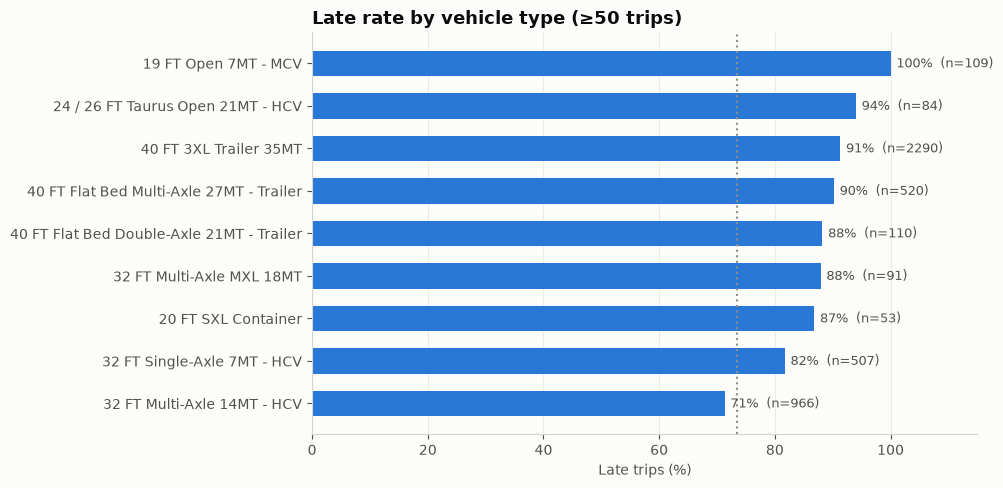

,trips,late_rate,median_delay_h_when_late
distance_band,,,
<100 km,2331,83.3,162.0
100–300 km,1097,53.4,155.0
300–600 km,521,55.7,149.0
600–1000 km,392,60.2,117.0
1000+ km,1360,80.7,82.0


In [16]:
by_vehicle = late_table("vehicleType")
late_bar(by_vehicle, "Late rate by vehicle type (≥50 trips)")
by_distance = late_table("distance_band").sort_index()
by_distance

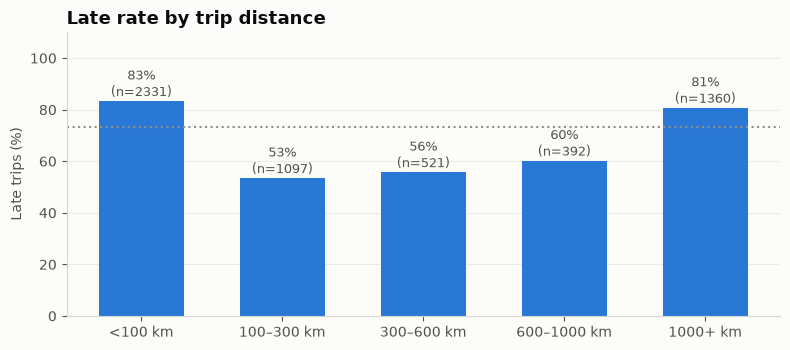

In [17]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(by_distance.index.astype(str), by_distance["late_rate"], color=BLUE, width=0.6)
for i, (r, n) in enumerate(zip(by_distance["late_rate"], by_distance["trips"])):
    ax.text(i, r + 2, f"{r:.0f}%\n(n={n})", ha="center", color=INK2, fontsize=9)
ax.axhline(late_rate * 100, color=GREY, linestyle=":", linewidth=1.5)
ax.set_ylim(0, 110); ax.set_ylabel("Late trips (%)"); ax.grid(axis="x", visible=False)
ax.set_title("Late rate by trip distance"); plt.tight_layout(); plt.show()

**Takeaways**
- **Big trailers (40 ft, 3XL, flat-bed) are late on about 90% of trips.** The 32 ft multi-axle 14 MT truck does best (71%).
- Distance shows a **U-shape**: very short trips (<100 km, 83% late) and very long ones (1000+ km, 81%) are worst, while 100–1000 km trips are late about 55% of the time. Short trips are mostly Larsen & Toubro project deliveries, so the customer effect is mixed in here.

### 5d. By route (≥30 trips)

48 routes have at least 30 tracked trips (out of 765 routes in total)


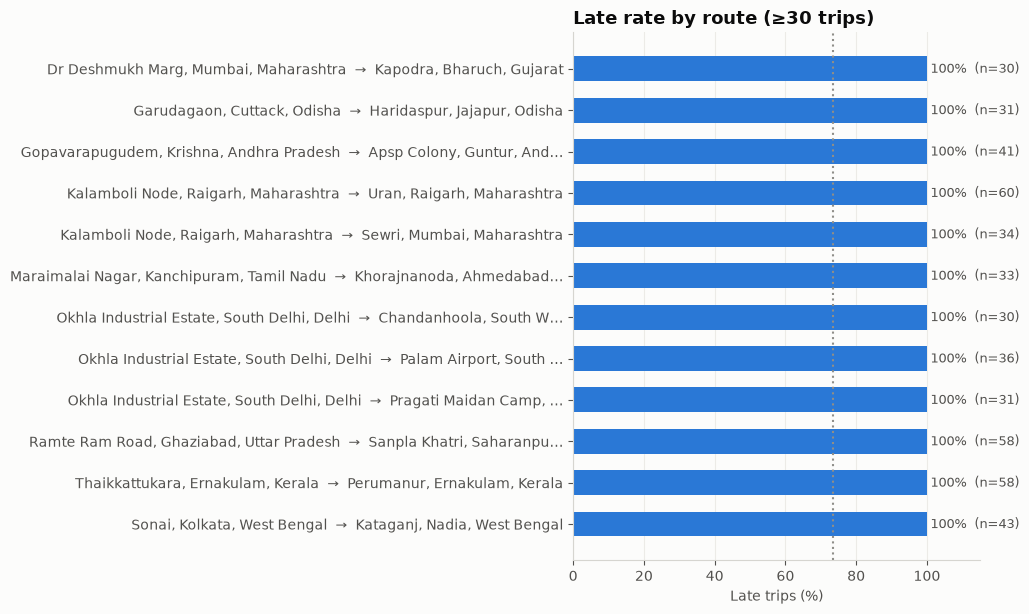

,trips,late_rate,median_delay_h_when_late
route,,,
"Dr Deshmukh Marg, Mumbai, Maharashtra → Kapodra, Bharuch, Gujarat",30,100.0,142.0
"Garudagaon, Cuttack, Odisha → Haridaspur, Jajapur, Odisha",31,100.0,174.0
"Gopavarapugudem, Krishna, Andhra Pradesh → Apsp Colony, Guntur, Andhra Pradesh",41,100.0,169.0
"Kalamboli Node, Raigarh, Maharashtra → Uran, Raigarh, Maharashtra",60,100.0,125.0
"Kalamboli Node, Raigarh, Maharashtra → Sewri, Mumbai, Maharashtra",34,100.0,394.0
"Maraimalai Nagar, Kanchipuram, Tamil Nadu → Khorajnanoda, Ahmedabad, Gujarat",33,100.0,112.0
"Okhla Industrial Estate, South Delhi, Delhi → Chandanhoola, South West Delhi, Delhi",30,100.0,958.0
"Okhla Industrial Estate, South Delhi, Delhi → Palam Airport, South West Delhi, Delhi",36,100.0,161.0
"Okhla Industrial Estate, South Delhi, Delhi → Pragati Maidan Camp, Central Delhi, Delhi",31,100.0,622.0


In [18]:
by_route = late_table("route", min_trips=30)
print(f"{len(by_route)} routes have at least 30 tracked trips (out of {tracked['route'].nunique()} routes in total)")
late_bar(by_route, "Late rate by route (≥30 trips)", top=12, label_width=70)
by_route.head(12)

**Takeaways**
- Only **48 of 765 routes** have enough tracked trips (≥30) to judge, which shows how scattered the network is.
- **13 regular routes were late on every trip**, including three from Okhla Industrial Estate (Delhi) and two from Kalamboli (Navi Mumbai). These are concrete, repeatable lanes where planned transit times are clearly unrealistic.

## 6. How much does the tracking provider matter?

On-time status depends on GPS tracking, so the tracking method itself can change the result. If one provider almost never shows a late trip and another almost always does, that points at **how** trips are recorded, not only at how they are driven. (This section uses all trips, so the untracked group is included for comparison.)

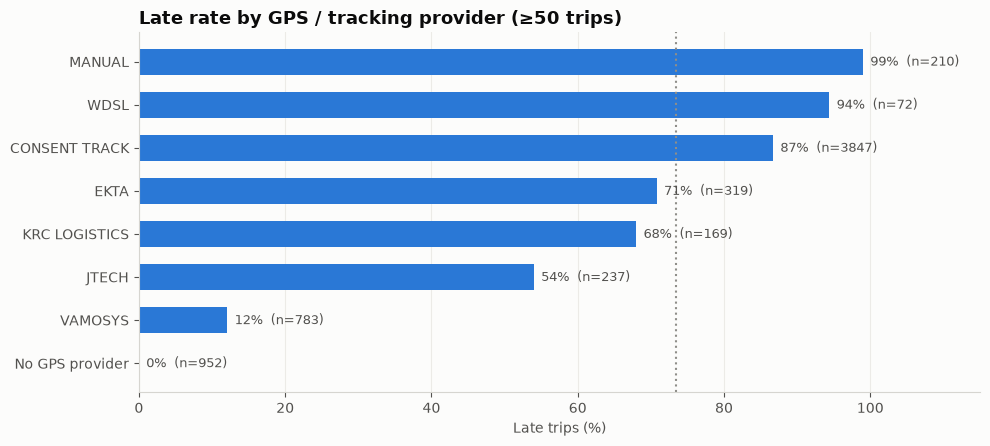

,trips,late_rate,median_delay_h_when_late
gps,,,
MANUAL,210,99.0,72.0
WDSL,72,94.4,51.0
CONSENT TRACK,3847,86.7,163.0
EKTA,319,70.8,63.0
KRC LOGISTICS,169,68.0,70.0
JTECH,237,54.0,66.0
VAMOSYS,783,12.1,54.0
No GPS provider,952,0.0,NaN


In [19]:
by_gps = late_table("gps", data=df)
late_bar(by_gps, "Late rate by GPS / tracking provider (≥50 trips)")
by_gps

In [20]:
# Also check: how complete is each important field, by tracking provider?
cols = ["Data_Ping_time", "Current_Location", "trip_end_date", "TRANSPORTATION_DISTANCE_IN_KM", "vehicleType", "Driver_Name"]
completeness = (df.groupby("gps")[cols].apply(lambda g: g.notna().mean() * 100).round(0))
completeness[df["gps"].value_counts().reindex(completeness.index) >= 50]

,Data_Ping_time,Current_Location,trip_end_date,TRANSPORTATION_DISTANCE_IN_KM,vehicleType,Driver_Name
gps,,,,,,
CONSENT TRACK,100.0,100.0,97.0,98.0,97.0,49.0
EKTA,100.0,100.0,96.0,94.0,100.0,100.0
JTECH,100.0,100.0,100.0,95.0,100.0,22.0
KRC LOGISTICS,100.0,100.0,98.0,98.0,95.0,100.0
MANUAL,100.0,100.0,100.0,100.0,100.0,0.0
No GPS provider,0.0,0.0,100.0,43.0,100.0,0.0
VAMOSYS,100.0,100.0,95.0,98.0,23.0,99.0
WDSL,100.0,100.0,100.0,88.0,100.0,0.0


**Takeaways**
- The late rate swings from **12% (VAMOSYS) to 99% (MANUAL)** depending on the tracking provider. That's too wide to be explained by driving alone.
- VAMOSYS mainly tracks the punctual automotive customers (Daimler, Lucas TVS, Ashok Leyland), while MANUAL and WDSL were used in mid-2019 when nearly everything was late. Provider, customer and period are tangled together.
- Tracking gaps: untracked trips have **no location data at all**, MANUAL/WDSL record **no driver names**, and VAMOSYS records vehicle type for only **23%** of trips.

## 7. Drivers: spread, not a name-and-shame list

Half of the driver names are missing, and most drivers have only a handful of trips, so ranking individual drivers would be unreliable and unfair. Instead we look at **how much drivers with a meaningful number of trips differ**.

Tracked trips with a driver name: 58%
Distinct drivers: 1,351 | with ≥10 trips: 48
count    48.00
mean      0.43
std       0.35
min       0.00
10%       0.00
25%       0.02
50%       0.50
75%       0.72
90%       0.90
max       1.00


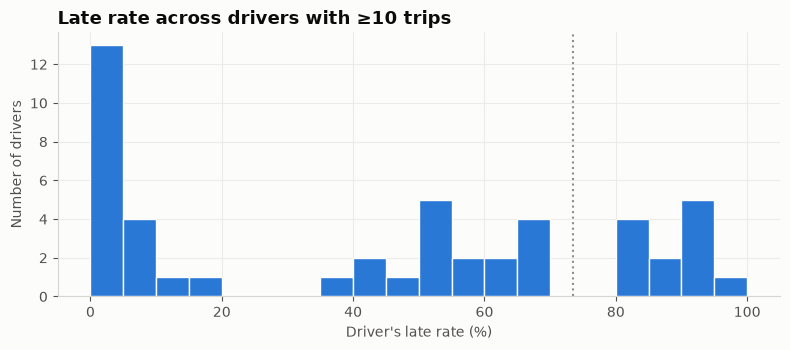

In [21]:
drv = tracked.dropna(subset=["Driver_Name"]).groupby("Driver_Name")["late"].agg(trips="size", late_rate="mean")
print(f"Tracked trips with a driver name: {tracked['Driver_Name'].notna().mean():.0%}")
print(f"Distinct drivers: {len(drv):,} | with ≥10 trips: {(drv['trips'] >= 10).sum()}")
reliable = drv[drv["trips"] >= 10]
print(reliable["late_rate"].describe(percentiles=[.1, .25, .5, .75, .9]).round(2).to_string())

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(reliable["late_rate"] * 100, bins=20, color=BLUE, edgecolor="#fcfcfb")
ax.axvline(late_rate * 100, color=GREY, linestyle=":", linewidth=1.5)
ax.set_xlabel("Driver's late rate (%)"); ax.set_ylabel("Number of drivers")
ax.set_title("Late rate across drivers with ≥10 trips"); plt.tight_layout(); plt.show()

**Takeaways**
- Only **48 drivers** have 10 or more tracked trips, too few to rank individuals fairly.
- Among them the spread is wide: **37% are late on at most 1 in 10 trips**, while **13% are late on 9 in 10 or more**. Driver habits may matter, but they're tied up with which customer and route each driver serves.

## 8. Key insights

1. **The data had to be fixed before it could be trusted.** 952 trips (14%) have no GPS, and their arrival time was copied from the plan, so they always look "on time". All KPIs use the 5,884 tracked trips.
2. **On-time performance is poor:** 73.5% of tracked trips are late, and the median late trip is about 6 days behind plan.
3. **About 1 in 7 late trips (622) is over 30 days late**, which almost certainly means trips not closed in the system rather than real delays.
4. **Delays are concentrated, not random:** a few customers (Kone, Otis, Ericsson, Larsen & Toubro), six suppliers late on every trip, large trailers, and 13 regular routes late on every trip.
5. **It is improving:** late rates dropped from about 99% (late 2019) to 34% in August 2020.
6. **Good examples already exist:** Ashok Leyland, Daimler and Lucas TVS shipments are mostly on time and can be used as the benchmark.

## 9. Recommendations

| Priority | Action | Why (evidence) |
|---|---|---|
| 1 | **Make tracking mandatory, and auto-close trips** when the truck reaches its destination geofence | 952 trips have no real arrival time; 622 late trips sit 30+ days open |
| 2 | **Re-plan transit times on the 13 routes that were late on every trip**, starting with the Okhla (Delhi) and Kalamboli (Navi Mumbai) lanes | 100% late over 30–60 trips each means the plan is unrealistic, not unlucky |
| 3 | **Review the six suppliers late on 100% of trips** in quarterly business reviews, with on-time targets in contracts | 57–183 trips each, all late |
| 4 | **Set separate ETA rules for 40 ft trailers and for Larsen & Toubro project loads** | ~90% late; L&T is over half of all tracked trips |
| 5 | **Copy what works on the Daimler, Lucas TVS and Ashok Leyland runs** (dedicated carriers, short regular lanes, good tracking) | 9–27% late vs 73.5% overall |
| 6 | **Fix data entry:** record driver, vehicle type and distance for every trip, and use one spelling per vehicle type | 50% of driver names and 11% of vehicle types missing; duplicate spellings found |

**Next step:** track monthly late rate and median delay on tracked trips as the two headline KPIs, and re-run this notebook each month to confirm the mid-2020 improvement holds.

## Notes and limitations
- The Excel file also contains sheets *Refined* and *Q1–Q10*. They use different dates (2015), add fields that are not in the trip data (weather, ratings, costs), and some (traffic counts, EV vs petrol costs) aren't about these trips at all. They look like separately prepared exercise data, so this analysis uses only *Primary data*.
- "Late" uses the dataset's own label. It matches the timestamps for ~99% of trips, but it is only as reliable as the tracking behind it (Sections 2 and 6).
- Customers, suppliers and routes are partly tied to *when* they shipped and *which tracker* they used, so a high late rate is a reason to investigate, not proof that a supplier drives badly.
- Groups with few trips are left out of rankings on purpose. Their late rates are too noisy to act on.